**Cell 1 — Install the libraries**

In [2]:
%pip install -q "pandas==2.2.3" scanpy h5py scipy numpy matplotlib seaborn

Cell 2 — Import libraries and define the dataset

In [3]:

from pathlib import Path
import urllib.request
import hashlib
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scanpy as sc
from scipy import sparse

SEED = 42
np.random.seed(SEED)

PROJECT_DIR = Path("/content/spatial-transcriptomics-project")
DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results" / "figures"

DATA_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

BASE_URL = (
    "https://cf.10xgenomics.com/samples/xenium/1.0.1/"
    "Xenium_FFPE_Human_Breast_Cancer_Rep1/"
    "Xenium_FFPE_Human_Breast_Cancer_Rep1"
)

MATRIX_URL = BASE_URL + "_cell_feature_matrix.h5"
CELLS_URL = BASE_URL + "_cells.csv.gz"

MATRIX_PATH = DATA_DIR / "cell_feature_matrix.h5"
CELLS_PATH = DATA_DIR / "cells.csv.gz"

print("Scanpy:", sc.__version__)
print("Project directory:", PROJECT_DIR)


Scanpy: 1.12
Project directory: /content/spatial-transcriptomics-project


/tmp/ipykernel_1785/2623390742.py:34: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("Scanpy:", sc.__version__)


Cell 3 — Download the data

In [5]:
import shutil

def download_file(url, destination):
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already downloaded: {destination.name}")
        return

    print(f"Downloading {destination.name}...")

    # Use a custom User-Agent to prevent 403 Forbidden errors
    req = urllib.request.Request(
        url,
        headers={'User-Agent': 'Mozilla/5.0 (Windows NT 10.0; Win64; x64)'}
    )

    try:
        with urllib.request.urlopen(req) as response, open(destination, 'wb') as out_file:
            shutil.copyfileobj(response, out_file)
    except Exception as e:
        destination.unlink(missing_ok=True)
        raise e

    if destination.stat().st_size == 0:
        destination.unlink(missing_ok=True)
        raise RuntimeError(f"Downloaded file is empty: {destination.name}")

    print(f"Saved: {destination.name} "
          f"({destination.stat().st_size / 1e6:.1f} MB)")


download_file(MATRIX_URL, MATRIX_PATH)
download_file(CELLS_URL, CELLS_PATH)

Saved: cell_feature_matrix.h5 (12.1 MB)
Saved: cells.csv.gz (7.9 MB)


Cell 4 — Load the expression matrix

In [6]:

adata = sc.read_10x_h5(MATRIX_PATH)

# Make gene names unique if any are duplicated.
adata.var_names_make_unique()

print("Expression matrix loaded successfully")
print(f"Cells: {adata.n_obs:,}")
print(f"Genes: {adata.n_vars:,}")
print("First five genes:", list(adata.var_names[:5]))
print("Matrix type:", type(adata.X))


Expression matrix loaded successfully
Cells: 167,780
Genes: 313
First five genes: ['ABCC11', 'ACTA2', 'ACTG2', 'ADAM9', 'ADGRE5']
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>


Cell 5 — Inspect the cell metadata

In [7]:

cells = pd.read_csv(CELLS_PATH)

print("Metadata dimensions:", cells.shape)
print("\nAvailable columns:")
print(cells.columns.tolist())

display(cells.head())


Metadata dimensions: (167780, 9)

Available columns:
['cell_id', 'x_centroid', 'y_centroid', 'transcript_counts', 'control_probe_counts', 'control_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area']


,cell_id,x_centroid,y_centroid,transcript_counts,control_probe_counts,control_codeword_counts,total_counts,cell_area,nucleus_area
0,1,847.259912,326.191365,28,1,0,29,58.387031,26.642187
1,2,826.341995,328.031830,94,0,0,94,197.016719,42.130781
2,3,848.766919,331.743187,9,0,0,9,16.256250,12.688906
3,4,824.228409,334.252643,11,0,0,11,42.311406,10.069844
4,5,841.357538,332.242505,48,0,0,48,107.652500,37.479687


Cell 6 — Calculate basic quality-control metrics

,count,mean,std,min,25%,50%,75%,max
total_transcripts,167780.0,191.34,129.43,0.0,96.0,164.0,262.0,1359.0
detected_genes,167780.0,63.20,24.55,0.0,48.0,64.0,79.0,194.0


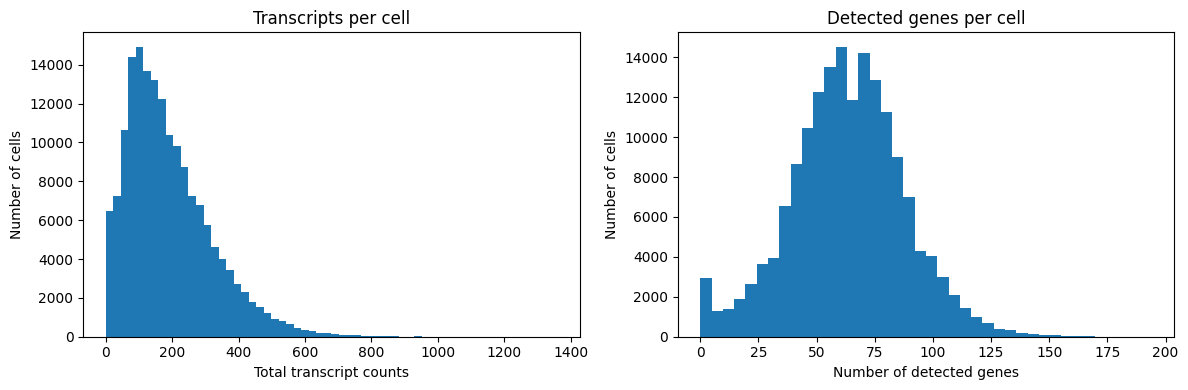

In [8]:

# Basic QC metrics from the expression matrix.
adata.obs["total_transcripts"] = np.asarray(
    adata.X.sum(axis=1)
).ravel()

adata.obs["detected_genes"] = np.asarray(
    (adata.X > 0).sum(axis=1)
).ravel()

qc_summary = adata.obs[
    ["total_transcripts", "detected_genes"]
].describe().T

display(qc_summary.round(2))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(
    adata.obs["total_transcripts"],
    bins=60
)
axes[0].set_title("Transcripts per cell")
axes[0].set_xlabel("Total transcript counts")
axes[0].set_ylabel("Number of cells")

axes[1].hist(
    adata.obs["detected_genes"],
    bins=40
)
axes[1].set_title("Detected genes per cell")
axes[1].set_xlabel("Number of detected genes")
axes[1].set_ylabel("Number of cells")

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "initial_qc_distributions.png",
    dpi=200,
    bbox_inches="tight"
)
plt.show()


Cell 7 — Check cell identifiers

In [9]:

print("Expression matrix cell IDs:")
print(adata.obs_names[:10].tolist())

print("\nMetadata cell IDs:")
print(cells["cell_id"].head(10).tolist())

print("\nUnique matrix IDs:", adata.obs_names.is_unique)
print("Unique metadata IDs:", cells["cell_id"].is_unique)


Expression matrix cell IDs:
['1', '2', '3', '4', '5', '6', '7', '8', '9', '10']

Metadata cell IDs:
[1, 2, 3, 4, 5, 6, 7, 8, 9, 10]

Unique matrix IDs: True
Unique metadata IDs: True


Cell 8 — Match the cells safely

In [10]:

# Work on copies to preserve the original data.
expr_ids = pd.Index(adata.obs_names.astype(str))
meta = cells.copy()

# First try an exact match. If that fails, test a common
# Xenium naming convention: a "cell_" prefix.
meta_ids = meta["cell_id"].astype(str)

if expr_ids.equals(pd.Index(meta_ids)):
    meta["match_id"] = meta_ids

elif set(expr_ids) == set(meta_ids):
    meta["match_id"] = meta_ids

else:
    matrix_normalized = expr_ids.str.replace(
        r"^cell_", "", regex=True
    )
    metadata_normalized = meta_ids.str.replace(
        r"^cell_", "", regex=True
    )

    if (
        matrix_normalized.is_unique
        and metadata_normalized.is_unique
        and set(matrix_normalized) == set(metadata_normalized)
    ):
        meta["match_id"] = metadata_normalized
        expr_ids = matrix_normalized
    else:
        raise ValueError(
            "Cell IDs could not be matched safely. "
            "Inspect the IDs before proceeding."
        )

# Reorder metadata to match expression matrix rows.
meta = meta.set_index("match_id").loc[expr_ids].copy()

assert len(meta) == adata.n_obs
assert meta.index.equals(expr_ids)

# Attach spatial coordinates and metadata to AnnData.
for col in [
    "x_centroid", "y_centroid", "cell_area",
    "nucleus_area", "transcript_counts"
]:
    adata.obs[col] = meta[col].to_numpy()

adata.obsm["spatial"] = meta[
    ["x_centroid", "y_centroid"]
].to_numpy(dtype=float)

print("Matched cells:", len(meta))
print("Spatial coordinates:", adata.obsm["spatial"].shape)
print("Missing coordinates:",
      np.isnan(adata.obsm["spatial"]).any(axis=1).sum())


Matched cells: 167780
Spatial coordinates: (167780, 2)
Missing coordinates: 0


Cell 9 — Plot cells by transcript abundance

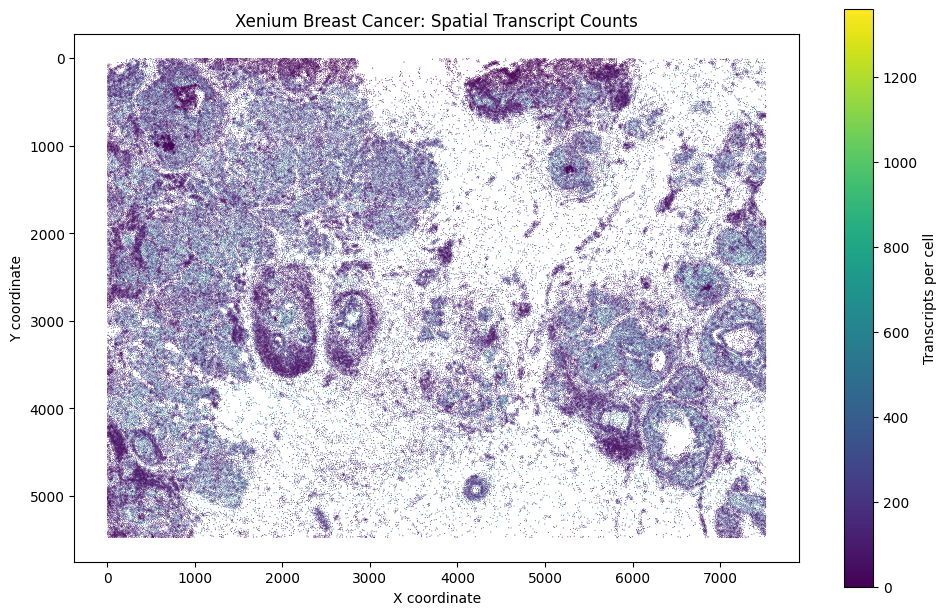

In [11]:

xy = adata.obsm["spatial"]
counts = adata.obs["total_transcripts"].to_numpy()

fig, ax = plt.subplots(figsize=(10, 8))

points = ax.scatter(
    xy[:, 0],
    xy[:, 1],
    c=counts,
    s=0.5,
    cmap="viridis",
    linewidths=0,
    rasterized=True
)

fig.colorbar(
    points, ax=ax, label="Transcripts per cell",
    shrink=0.75
)

ax.set_title("Xenium Breast Cancer: Spatial Transcript Counts")
ax.set_xlabel("X coordinate")
ax.set_ylabel("Y coordinate")
ax.set_aspect("equal")

# Preserve the coordinate orientation from the dataset.
ax.invert_yaxis()

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "spatial_transcript_counts.png",
    dpi=250,
    bbox_inches="tight"
)
plt.show()


Cell 10 — Search for marker genes

In [12]:

genes_to_check = [
    "EPCAM", "KRT8", "KRT18", "KRT19",  # epithelial-associated
    "PTPRC", "CD3D", "CD3E",             # immune-associated
    "CD68", "CD74", "MS4A1",             # immune-cell markers
    "COL1A1", "ACTA2", "PECAM1"          # stromal / vascular markers
]

available = [
    gene for gene in genes_to_check
    if gene in adata.var_names
]

missing = [
    gene for gene in genes_to_check
    if gene not in adata.var_names
]

print("Available genes:", available)
print("Not in panel:", missing)


Available genes: ['EPCAM', 'KRT8', 'PTPRC', 'CD3D', 'CD3E', 'CD68', 'MS4A1', 'ACTA2', 'PECAM1']
Not in panel: ['KRT18', 'KRT19', 'CD74', 'COL1A1']


Cell 11 — Plot the first available marker

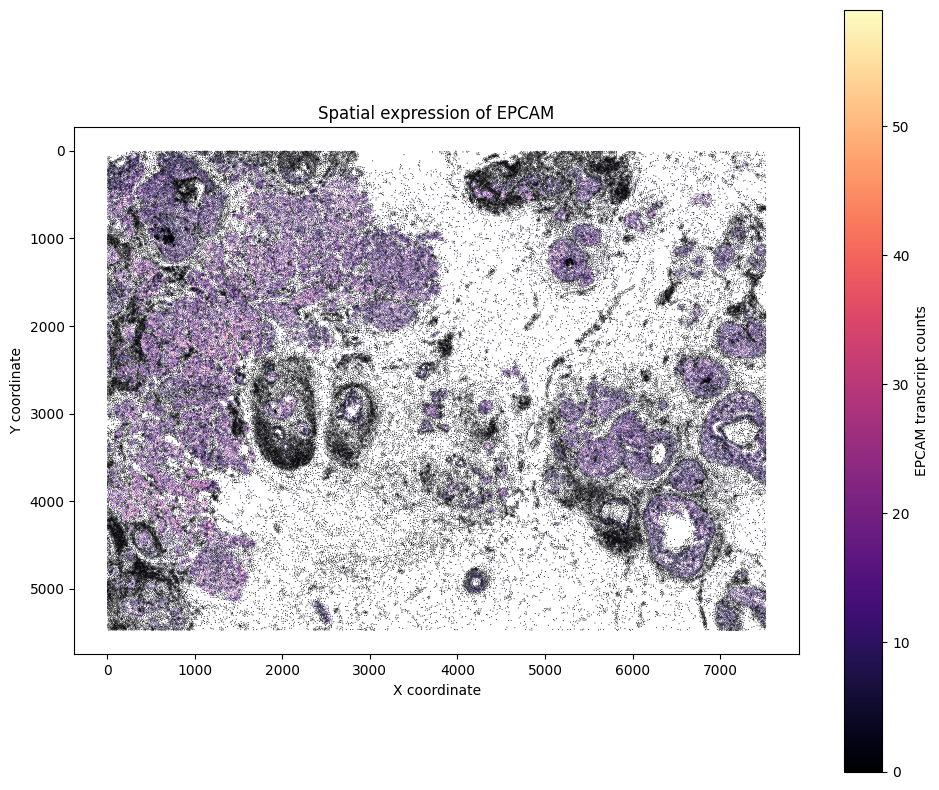

In [13]:

if not available:
    print("None of the candidate markers were found.")
    print("Available genes:", adata.var_names.tolist())
else:
    gene = available[0]
    values = np.asarray(
        adata[:, gene].X.toarray()
    ).ravel()

    fig, ax = plt.subplots(figsize=(10, 8))

    points = ax.scatter(
        xy[:, 0],
        xy[:, 1],
        c=values,
        s=0.5,
        cmap="magma",
        linewidths=0,
        rasterized=True
    )

    fig.colorbar(points, ax=ax, label=f"{gene} transcript counts")
    ax.set_title(f"Spatial expression of {gene}")
    ax.set_xlabel("X coordinate")
    ax.set_ylabel("Y coordinate")
    ax.set_aspect("equal")
    ax.invert_yaxis()

    plt.tight_layout()
    plt.savefig(
        RESULTS_DIR / f"spatial_{gene}.png",
        dpi=250,
        bbox_inches="tight"
    )
    plt.show()


In [14]:

# Save a compact QC summary.
qc_summary.to_csv(PROJECT_DIR / "qc_summary.csv")

# Record dataset dimensions and analysis settings.
manifest = {
    "dataset": "Xenium FFPE Human Breast Cancer Replicate 1",
    "cells": int(adata.n_obs),
    "genes": int(adata.n_vars),
    "random_seed": SEED,
    "python_analysis": "Scanpy / AnnData",
    "coordinate_columns": ["x_centroid", "y_centroid"],
    "figures": sorted(
        p.name for p in RESULTS_DIR.glob("*.png")
    ),
}

with open(PROJECT_DIR / "analysis_manifest.json", "w") as f:
    json.dump(manifest, f, indent=2)

print(json.dumps(manifest, indent=2))
print("\nOutput directory:", PROJECT_DIR)


{
  "dataset": "Xenium FFPE Human Breast Cancer Replicate 1",
  "cells": 167780,
  "genes": 313,
  "random_seed": 42,
  "python_analysis": "Scanpy / AnnData",
  "coordinate_columns": [
    "x_centroid",
    "y_centroid"
  ],
  "figures": [
    "initial_qc_distributions.png",
    "spatial_EPCAM.png",
    "spatial_transcript_counts.png"
  ]
}

Output directory: /content/spatial-transcriptomics-project
